In [1]:
"""
This notebook aligns extracted metastasis data, which is missing many features, with the corresponding data from the full dataset.
"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import os

extracted_path = "extracted_met_data"
cluster_path = "complete_cluster_data"

In [2]:
### UTILITIES
phenos = ["PhenotypeCD206", "PhenotypeCD3", "PhenotypeCD8", "PhenotypeFoxp3", "PhenotypeGR1", "PhenotypeHER2", "PhenotypeMHCII", "PhenotypeNCR1"]
bad_cells = ["error_type", "unknown", "immune"]

# Function that concatenates the "tag" and the "CellID"
def assemble_UID(row):
    tag = row["tag"]
    cellID = row["CellID"]
    return tag + str(cellID)

# Function that applies cell type
markers = ["CD206", "CD3", "CD8", "Foxp3", "GR1", "HER2", "MHCII", "NCR1"] # THIS ORDER SHOULD NOT BE CHANGED
missing_combos = []
def identify_celltype(row, lookup_table, tx_data = False):
    # Lookup table should be either a dict with int : str or properly-ordered list of cell types
    states = []
    for i, marker in enumerate(markers):
        if tx_data:
            if marker == "GR1":
                marker = "GR-1"
            string = f"Phenotype {marker}"
        else:
            string = f"Phenotype{marker}"
        states.append(get_bool(row[string]))
    if 2 in states:
        # If there is any <unknown> annotation the cell is unknown
        return "error_type"
    else:
        # Else we can proceed to obtain the unique combination ID
        # We reverse the string because in Excel the #s were generated least sig -> most sig
        combination = int("".join(str(bit) for bit in states[::-1]), 2)
    if combination in lookup_table.keys():
        return lookup_table[combination]
    else:
        missing_combos.append(combination)
        return "unknown"

# Phenotype lookup table
binary_classifications = pd.read_excel("BinaryCellClassification.xlsx", usecols=["combination", "cell_type"],
                                      skipfooter=1) # Last row is the error-row so is excluded
id_dict = dict(zip(binary_classifications["combination"], binary_classifications["cell_type"]))

# Helper function that returns what the phenotype is
def get_bool(phenotype):
    if type(phenotype) == float:
        return 2 # For now this is an error reached when a cell has nan
    identifier = phenotype[-1]
    if identifier == "-":
        return 0
    elif identifier == "+":
        return 1
    else:
        return 2

# Create colormaps used to plot
import matplotlib.colors as mcolors
paired = plt.cm.Paired.colors
paired_to9 = mcolors.ListedColormap(paired[:9])
paired_to11 = mcolors.ListedColormap(paired[:11])

colormap = {
    1 : 0, # M1 macrophage
    2 : 1, # M2 macrophage
    3 : 2, # cancer
    4 : 3, # Th
    5 : 4, # Treg
    6 : 5, # CD8
    8 : 6, # NK
    10 : 7, # MDSC
    -10 : 8 # errortype or unknown
} 

cell_colors = [
    'xkcd:lilac', # M0
    'xkcd:bright purple', # M1
    'tab:pink', # M2
    'tab:blue', # cancer
    'tab:green', # CD4 T helper
    'lime', # CD4 TReg
    'tab:orange', # CD8
    'tab:brown', # NK cell
    'xkcd:goldenrod', # MDSC
    'darkgray', # Unknown cell
    'tab:red', # Error-type
    'lightcoral' # Generalized immune
]

cell_cmap = mcolors.ListedColormap(cell_colors)
#fig, ax = plt.subplots()
#fig.set_dpi(300)
#ax.imshow([np.arange(len(cell_colors))], cmap=cell_cmap)
#ax.set_xticks(np.arange(len(cell_colors)), ["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unk", "Err", "Imm"], rotation=-45)
#ax.set(title="Colormap for available cell types")
#ax.yaxis.set_visible(False)

name_to_type = {
    "M1" : 0, # M1 macrophage
    "M2" : 1, # M2 macrophage
    "cancer" : 2, # cancer
    "CD4" : 3, # Th
    "Treg" : 4, # Treg
    "treg" : 4, # also Treg
    "TReg" : 4, # Treg
    "CD8" : 5, # CD8
    "NK" : 6, # NK
    "MDSC" : 7, # MDSC
    "unknown" : 8, # errortype or unknown
    "error_type" : 9, # errortype or unknown
    "immune" : 10 # errortype or unknown
}


apply_cmap = lambda x : colormap[x]
apply_type = lambda x : name_to_type[x]

plt.style.use('dark_background')

In [ ]:
# This cell will eliminate reference clusters that have > 40000 cells and extracted metastases that have > 20000 cells
# This eliminates structures that are predominantly lymphoid that will take a long time to run
# If you've laready generated the CSVs you do not need to re-generate them

import time

full_data = os.listdir(cluster_path)
met_folders = os.listdir(extracted_path)
met_folders.sort()

for met_folder in met_folders:
    
    print(f"\n Analyzing {met_folder}... ")
    
    # Get the corresponding element in the full_data list
    data_pair = met_folder[:-10] + ".csv"
    if data_pair not in full_data:
        print(f"ERROR: data pair not found for file {met_folder}.")

    paired_data = pd.read_csv(os.path.join(cluster_path, data_pair))
    print(f"The reference data set {data_pair} has {len(paired_data)} members.")
    if len(paired_data) > 40000:
        print(f"The reference cluster is too large... skipping")
        continue

    # Get data
    path_to_file = os.path.join(extracted_path, met_folder)

    # Loop here because there may be multiple! subfiles
    for subfile in os.listdir(path_to_file):
        if subfile[-4:] == ".csv":

            # This loops over all the data to see if the location occurs in both DFs
            start = time.time()
            base_data = pd.read_csv(os.path.join(path_to_file, subfile))
            if len(base_data) > 20000:
                print(f"The extracted metastasis is too large... skipping")
                continue
                
            keys = base_data[["shiftedData1", "shiftedData2"]].to_numpy()
            paired_data["loc_pair"] = list(paired_data[["shiftedData1", "shiftedData2"]].to_numpy())
            base = np.all(keys[0] == list(paired_data["loc_pair"]), axis=1)
            for i in range(len(keys) - 1):
                base += np.all(keys[i + 1] == list(paired_data["loc_pair"]), axis=1)

            # Extract the overlap from the full csv
            extracted = paired_data[base]

            # Sanity check!
            end = time.time()
            print(f"Base_data has {len(base_data)} members and we extracted {len(extracted)} members in {end-start:.2f} s.")

            # Save data
            extracted.to_csv(os.path.join("extracted_met_full", subfile))

In [3]:
import joblib

plt.style.use('dark_background')
cell_names = ["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unknown", "Error", "Immune"] # Proper names
cell_types = ["M0", "M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC", "unknown", "error_type", "immune"] # Names in the data
reextracted_path = "extracted_met_full" # Location of the re-extracted data
rf_file = "all_nontx_data_rf.joblib" # Location of the saved random forest model

rf = joblib.load(rf_file) # Load in the RF
rf.set_params(verbose=False)
fnames = rf.feature_names_in_ # Get the feature names
classes = rf.classes_

names = []
vc_orig = []
vc_top_pred = []
scores = []
pred_dfs = []
locs = []
predicted_met_dfs = []

do_plotting = False
pd.options.mode.chained_assignment = None

for file in os.listdir(reextracted_path):

    if file[-4:] != ".csv":
        print(file[-4:])
        continue
    
    data = pd.read_csv(os.path.join(reextracted_path, file)) # Get the data
    data["celltype"] = data[phenos].apply(identify_celltype, args=[id_dict], axis=1) # Get celltype
    data["celltype"].replace({"Treg":"TReg", "treg":"Treg"})
    unk = pd.concat([data[data["celltype"] == "unknown"], data[data["celltype"] == "immune"]]) 
    known = data[data["celltype"] != "unknown"]
    known = known[known["celltype"] != "immune"]
    
    probs = rf.predict_proba(unk[fnames]) # Gets the predicted probabilities
    top3 = [sorted(zip(prob_set, classes), reverse=True)[:3] for prob_set in probs] # Generates a list of tuples [(prob, class), (prob, class), (prob, class)]] for each element
    top3_class = np.array(top3)[:, :, 1]
    top3_probs = np.array(top3)[:, :, 0] 
    unk.loc[:, ["P1", "P2", "P3"]] = top3_class # Assign predicted classes back to the dataframe
    unk.loc[:, ["p_P1", "p_P2", "p_P3"]] = top3_probs # Assign predicted classes probabilities back to the dataframe

    # Value counts
    vc_orig.append(data["celltype"].value_counts()) # of original data
    vc_known = known["celltype"].value_counts()
    vc_unk = unk["P1"].value_counts()
    vc_top_pred.append(vc_unk) # of transformed unknowns
    names.append(file)

    # Scoring
    pot_map = vc_known.add(vc_unk, fill_value=0) # Combine top pred w/ already-labelled data
    for cell_type in cell_types:
        if cell_type not in pot_map.keys():
            pot_map[cell_type] = 0
            
    s_lymphoid = sum(pot_map[["CD4", "TReg", "CD8", "NK"]]) / sum(pot_map)
    s_myeloid = sum(pot_map[["M1", "M2", "MDSC"]]) / sum(pot_map)
    s_cancer = pot_map["cancer"] / sum(pot_map)
    s_mean_pP1 = np.mean(unk["p_P1"].to_numpy(dtype=np.float32))
    s_pP1_over50 = sum(unk["p_P1"].to_numpy(dtype=np.float32) >= 0.50) / len(unk["p_P1"])
    s_size = sum(pot_map)
    scores.append([s_lymphoid, s_myeloid, s_cancer, s_mean_pP1, s_pP1_over50, s_size])

    # Save info about the predictions
    loc = unk[["shiftedData1", "shiftedData2"]]
    locs.append(loc) # This saves the corresponding locations
    pred_dfs.append(probs) # These are just the unknowns
    unk_to_export = unk[["shiftedData1", "shiftedData2", "P1"]]
    unk_to_export.rename(columns={"P1" : "celltype"}, inplace=True)
    unk_to_export.loc[:, "origin"] = 1 
    known_to_export = known[["shiftedData1", "shiftedData2", "celltype"]]
    known_to_export = known_to_export[known_to_export["celltype"] != "error_type"]
    known_to_export.loc[:, "origin"] = 0
    to_export = pd.concat([known_to_export, unk_to_export], ignore_index = False)
    to_export["num_type"] = to_export["celltype"].apply(apply_type)
    predicted_met_dfs.append(to_export) # These are all cells
    
    # Plotting
    if do_plotting:
        fig, ax = plt.subplots(2, 4, figsize=(20, 10), dpi=300, layout='compressed')
    
        # Plot predictions
        ax[0, 0].scatter(unk["shiftedData1"], unk["shiftedData2"], c=unk["P1"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=.5)
        ax[0, 1].scatter(unk["shiftedData1"], unk["shiftedData2"], c=unk["P2"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=.5)
        ax[0, 2].scatter(unk["shiftedData1"], unk["shiftedData2"], c=unk["P3"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=.5)
    
        # Fill in with what we know
        ax[0, 0].scatter(known["shiftedData1"], known["shiftedData2"], c=known["celltype"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=.5, alpha = .5)
        ax[0, 0].set(title = "1st RF prediction")
        ax[0, 1].scatter(known["shiftedData1"], known["shiftedData2"], c=known["celltype"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=.5, alpha = .5)
        ax[0, 1].set(title = "2nd RF prediction")
        ax[0, 2].scatter(known["shiftedData1"], known["shiftedData2"], c=known["celltype"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=.5, alpha = .5)
        ax[0, 2].set(title = "3rd RF prediction")
    
        # Plot reference
        c = ax[0, 3].scatter(data["shiftedData1"], data["shiftedData2"], c=data["celltype"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=.5)
        ax[0, 3].set(title="Reference")
    
        # Colorbar
        cbar = plt.colorbar(c, ax=ax, location="right")
        cbar.set_ticks([-0.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5])
        cbar.set_ticklabels(cell_names)
    
        fig.suptitle(file[:-4])

        # Histograms for confidence
        p1_list = []
        p2_list = []
        p3_list = []
        for celltype in cell_types:
            p1_list.append(unk[unk["P1"] == celltype]["p_P1"].to_numpy(dtype=np.float32))
            p2_list.append(unk[unk["P2"] == celltype]["p_P2"].to_numpy(dtype=np.float32))
            p3_list.append(unk[unk["P3"] == celltype]["p_P3"].to_numpy(dtype=np.float32))
            
        ax[1, 0].hist(p1_list, 20, range=[0, 1], stacked=True, color=cell_colors)
        ax[1, 0].set(xlabel="prediction prob.")
        ax[1, 1].hist(p2_list, 20, range=[0, 1], stacked=True, color=cell_colors)
        ax[1, 1].set(xlabel="prediction prob.")
        ax[1, 2].hist(p3_list, 20, range=[0, 1], stacked=True, color=cell_colors)
        ax[1, 2].set(xlabel="prediction prob.")

        # Original data distribution
        a = data["celltype"].value_counts()
        for label in cell_types:
            if label not in a.keys():
                a[label] = 0
        a[cell_types].plot.bar(ax = ax[1, 3], color=cell_colors)
        ax[1, 3].set_xticks(np.arange(len(cell_names)), labels=cell_names)
        
        fig.savefig(os.path.join(reextracted_path, "images", file[:-4] + ".png"), dpi=300)
        plt.close(fig)

pd.options.mode.chained_assignment = 'warn'

.png
ints
ages
tion


In [4]:
scores_df = pd.DataFrame(scores, columns=["%_lymphoid", "%_myeloid", "%_cancer", "mean_pP1", "%_pP1_>50", "n_cells"])
scores_df["access_i"] = range(len(scores_df))
scores_df.index = names

# Apply filtering
l_size, u_size, max_lymphoid, avg_pP1_thresh = 500, 20000, 0.50, 0.40
subset = scores_df[scores_df["n_cells"] >= l_size]
subset = subset[subset["n_cells"] <= u_size]
subset = subset[subset["%_lymphoid"] <= max_lymphoid]
subset = subset[subset["mean_pP1"] >= avg_pP1_thresh]
subset.sort_values(["mean_pP1"], ascending=False)

,%_lymphoid,%_myeloid,%_cancer,mean_pP1,%_pP1_>50,n_cells,access_i
121223 P9msP61-2 #29 NeuN NT2.5 LM 4 wks #2_met_8_region1_points.csv,0.063651,0.200421,0.735402,0.622633,0.582313,1901.0,68
121223 P9msP61-2 #19 7 days Untx-1_met_1_region1_points.csv,0.342020,0.339848,0.280130,0.619045,0.659176,921.0,38
121223 P9msP61-2 #29 NeuN NT2.5 LM 4 wks #2_met_10_region1_points.csv,0.104332,0.418258,0.469958,0.608561,0.566849,2147.0,42
121223 P9msP61-2 #31 NeuN NT2.5 LM 4 wks #4_met_5_region1_points.csv,0.131547,0.204629,0.655298,0.580847,0.493671,2463.0,26
121223 P9msP61-2 #27 NeuN NT2.5 LM 5 wks #3_met_4_region1_points.csv,0.127354,0.484305,0.366816,0.573156,0.534653,1115.0,13
121223 P9msP61-2 #29 NeuN NT2.5 LM 4 wks #2_met_13_region1_points.csv,0.239437,0.461854,0.296948,0.551419,0.458669,1704.0,12
121223 P9msP61-2 #31 NeuN NT2.5 LM 4 wks #4_met_9_region1_points.csv,0.367816,0.312723,0.316686,0.547300,0.444500,2523.0,33
121223 P9msP61-2 #31 NeuN NT2.5 LM 4 wks #4_met_12_region1_points.csv,0.247133,0.140585,0.605623,0.535416,0.401109,2703.0,74
121223 P9msP61-2 #16 NT2.5 LM d122 V1_met_1_region1_points.csv,0.420949,0.495389,0.029644,0.534645,0.474498,1518.0,25
121223 P9msP61-2 #31 NeuN NT2.5 LM 4 wks #4_met_7_region1_points.csv,0.246444,0.107692,0.640058,0.527733,0.393327,3445.0,9


[Text(0.5, 1.0, 'Cell counts ($n_{tot}$ = 3179)')]

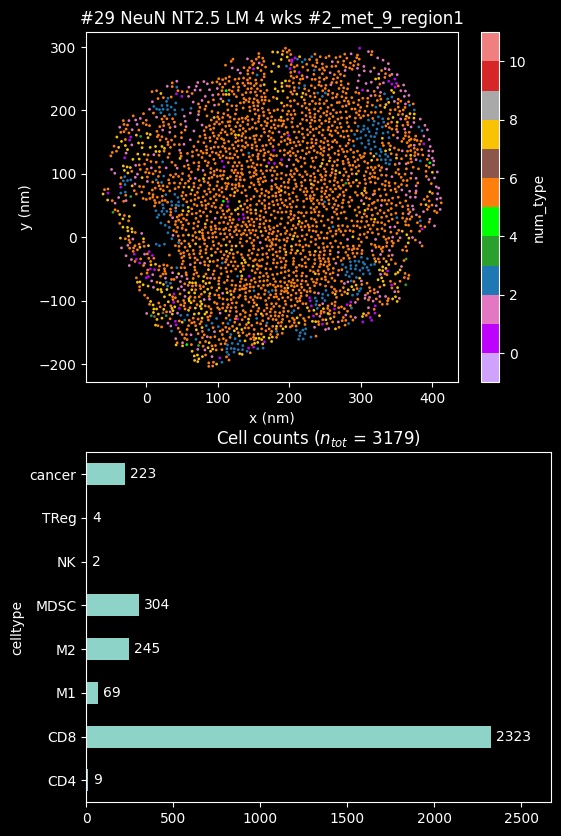

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(6, 10), dpi=100)

met_to_plot = 0
met = predicted_met_dfs[met_to_plot]
met = met.replace({"Treg":"TReg", "treg":"Treg"})
met.plot.scatter("shiftedData1", "shiftedData2", c="num_type", cmap=cell_cmap, clim=[-1, 11], s=1, ax=ax[0])
ax[0].set(title = names[met_to_plot][17:-11], xlabel="x (nm)", ylabel="y (nm)")

bars = met.groupby("celltype").count()["num_type"].transpose()
bars.plot.barh(ax=ax[1])
ax[1].set_xlim(0, max(bars)*1.15)
for p in ax[1].patches:
    ax[1].annotate(f"{p.get_width():d}", (p.get_width() + p.get_height()/200 + 25*(max(bars)/2000), p.get_center()[1]), va="center", ha="left")
ax[1].set(title = "Cell counts ($n_{tot}$ =" + f" {sum(bars)})")

#fig.tight_layout()

In [18]:
sample = [name[17:20] for name in names]

top8 = [sorted(zip(prob_set, classes), reverse=True)[:8] for prob_set in pred_dfs[0]]
top8_probs = np.array(top8)[:, :, 0]
top8_class = np.array(top8)[:, :, 1]
all_data = pd.DataFrame(pred_dfs[0], columns=rf.classes_)
all_data.loc[:, "sample"] = sample[0]
all_data.loc[:, "metastasis"] = names[0]
all_data.loc[:, "met_index"] = all_data.index
all_data.loc[:, "shiftedData1"] = list(locs[0]["shiftedData1"])
all_data.loc[:, "shiftedData2"] = list(locs[0]["shiftedData2"])
all_data.loc[:, ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8"]] = top8_class
all_data.loc[:, ["p_P1", "p_P2", "p_P3", "p_P4", "p_P5", "p_P6", "p_P7", "p_P8"]] = top8_probs

for i, data in enumerate(pred_dfs):
    if i != 0:
        top8 = [sorted(zip(prob_set, classes), reverse=True)[:8] for prob_set in data]
        top8_probs = np.array(top8)[:, :, 0]
        top8_class = np.array(top8)[:, :, 1]
        df = pd.DataFrame(data, columns=rf.classes_)
        df.loc[:, "sample"] = sample[i]
        df.loc[:, "metastasis"] = names[i]
        df.loc[:, "met_index"] = df.index
        df.loc[:, "shiftedData1"] = list(locs[i]["shiftedData1"])
        df.loc[:, "shiftedData2"] = list(locs[i]["shiftedData2"])
        df.loc[:, ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8"]] = top8_class
        df.loc[:, ["p_P1", "p_P2", "p_P3", "p_P4", "p_P5", "p_P6", "p_P7", "p_P8"]] = top8_probs
        all_data = pd.concat([all_data, df], axis=0, ignore_index=True)

In [ ]:
for this_sample in np.unique(sample):
    subset = all_data[all_data["sample"] == this_sample][["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "p_P1", "p_P2", "p_P3", "p_P4", "p_P5", "p_P6", "p_P7", "p_P8"]]

    # Histograms!
    p1_list = []
    p2_list = []
    p3_list = []
    for celltype in cell_types:
        p1_list.append(subset[subset["P1"] == celltype]["p_P1"].to_numpy(dtype=np.float32))
        p2_list.append(subset[subset["P2"] == celltype]["p_P2"].to_numpy(dtype=np.float32))
        p3_list.append(subset[subset["P3"] == celltype]["p_P3"].to_numpy(dtype=np.float32))

    # Plotting
    fig, ax = plt.subplots(1, 3, figsize=(15, 5), dpi=300)
    fig.suptitle("Sample " + this_sample + ", n_samples = " + str(sample.count(this_sample)))
    ax[0].hist(p1_list, 20, range=[0, 1], stacked=True, color=cell_colors)
    ax[0].set(xlabel="prediction prob.", title="RF pred. 1")
    ax[1].hist(p2_list, 20, range=[0, 1], stacked=True, color=cell_colors)
    ax[1].set(xlabel="prediction prob.", title="RF pred. 2")
    ax[2].hist(p3_list, 20, range=[0, 1], stacked=True, color=cell_colors)
    ax[2].set(xlabel="prediction prob.", title="RF pred. 3")

    fig.savefig(os.path.join(reextracted_path, "per_sample_composition", this_sample + ".png"), dpi=300)
    plt.close(fig)

In [31]:
all_data["shiftedData1"]

0         106.80
1         154.40
2          77.00
3         326.70
4         247.80
           ...  
169562    376.85
169563    477.65
169564    483.15
169565    479.15
169566    396.25
Name: shiftedData1, Length: 169567, dtype: float64

In [20]:
keep = all_data[all_data["p_P1"].astype(np.float64) >= 0.6]
reprocess = all_data[all_data["p_P1"].astype(np.float64) < 0.6]

print(f"We keep {len(keep)} cells with p_P1 > 0.6")
print(f"We identify {len(reprocess)} cells to reprocess")

We keep 42119 cells with p_P1 > 0.6
We identify 127448 cells to reprocess


[Text(0.5, 1.0, 'Ordered by std. (exc. small entries < 0.05)')]

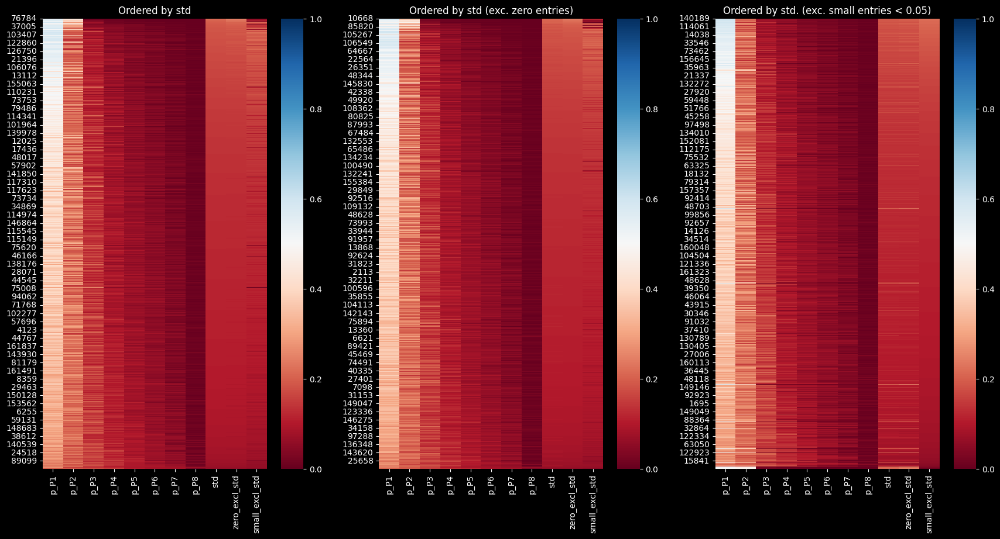

In [21]:
cell_rf_definition = reprocess[["M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC"]].astype(np.float64) # For clustering
cell_pred_definition = reprocess[["p_P1", "p_P2", "p_P3", "p_P4", "p_P5", "p_P6", "p_P7", "p_P8"]].astype(np.float64) # For thresholding

import seaborn as sns
values = ["p_P1", "p_P2", "p_P3", "p_P4", "p_P5", "p_P6", "p_P7", "p_P8"]
std = cell_pred_definition.std(axis=1, ddof=0)
zero_excl_std = cell_pred_definition.apply(lambda x: x[x != 0].std(ddof=0), axis=1)
small_excl_std = cell_pred_definition.apply(lambda x: x[x > 0.05].std(ddof=0), axis=1)
cell_pred_definition["std"] = std
cell_pred_definition["zero_excl_std"] = zero_excl_std
cell_pred_definition["small_excl_std"] = small_excl_std

cell_pred_definition.sort_values("std", axis=0, ascending=False, inplace=True)
fig, ax = plt.subplots(1, 3, figsize=(21, 10))
sns.heatmap(cell_pred_definition, ax = ax[0], cmap="RdBu", vmin=0, vmax=1)
ax[0].set(title="Ordered by std")

cell_pred_definition.sort_values("zero_excl_std", axis=0, ascending=False, inplace=True)
sns.heatmap(cell_pred_definition, ax = ax[1], cmap="RdBu", vmin=0, vmax=1)
ax[1].set(title="Ordered by std (exc. zero entries)")

cell_pred_definition.sort_values("small_excl_std", axis=0, ascending=False, inplace=True)
sns.heatmap(cell_pred_definition, ax = ax[2], cmap="RdBu", vmin=0, vmax=1)
ax[2].set(title="Ordered by std. (exc. small entries < 0.05)")

UMAP( verbose=True)
Thu Nov  6 17:02:27 2025 Construct fuzzy simplicial set
Thu Nov  6 17:02:27 2025 Finding Nearest Neighbors
Thu Nov  6 17:02:27 2025 Building RP forest with 23 trees
Thu Nov  6 17:02:33 2025 NN descent for 17 iterations
	 1  /  17
	 2  /  17
	Stopping threshold met -- exiting after 2 iterations
Thu Nov  6 17:02:49 2025 Finished Nearest Neighbor Search
Thu Nov  6 17:02:52 2025 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Thu Nov  6 17:03:30 2025 Finished embedding


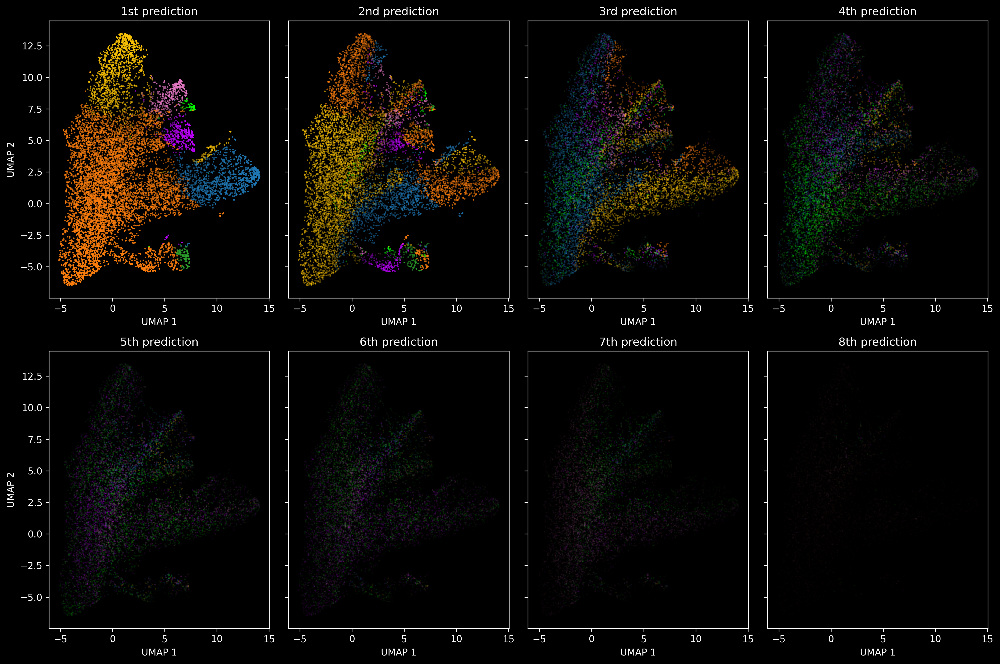

In [22]:
import umap

do_umap = True
if do_umap:
    umap = umap.UMAP(n_components=2, verbose=True)
    reprocess.loc[:, ["UMAP 1", "UMAP 2"]] = umap.fit_transform(reprocess[rf.classes_])

plt.style.use("dark_background")
fig, ax = plt.subplots(2, 4, figsize=(15, 10), dpi=300, sharey=True)
sample = reprocess.sample(10000)

# There are no NaN for the first 3 predictions
ax[0, 0].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P1"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P1"].to_numpy(dtype=np.float32))
ax[0, 0].set(title="1st prediction", xlabel="UMAP 1", ylabel="UMAP 2")
ax[0, 1].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P2"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P2"].to_numpy(dtype=np.float32))
ax[0, 1].set(title="2nd prediction", xlabel="UMAP 1")
ax[0, 2].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P3"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P3"].to_numpy(dtype=np.float32))
ax[0, 2].set(title="3rd prediction", xlabel="UMAP 1")

# Here we need to start dropping NaN from the list
sample = sample.dropna(axis=0, subset="P4")
ax[0, 3].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P4"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P4"].to_numpy(dtype=np.float32))
ax[0, 3].set(title="4th prediction", xlabel="UMAP 1")
sample = sample.dropna(axis=0, subset="P5")
ax[1, 0].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P5"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P5"].to_numpy(dtype=np.float32))
ax[1, 0].set(title="5th prediction", xlabel="UMAP 1", ylabel="UMAP 2")
sample = sample.dropna(axis=0, subset="P6")
ax[1, 1].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P6"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P6"].to_numpy(dtype=np.float32))
ax[1, 1].set(title="6th prediction", xlabel="UMAP 1")
sample = sample.dropna(axis=0, subset="P7")
ax[1, 2].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P7"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P7"].to_numpy(dtype=np.float32))
ax[1, 2].set(title="7th prediction", xlabel="UMAP 1")
sample = sample.dropna(axis=0, subset="P8")
ax[1, 3].scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["P8"].apply(apply_type), cmap=cell_cmap, clim=[-1, 11], s=0.5, alpha=(1/0.6)*sample["p_P8"].to_numpy(dtype=np.float32))
ax[1, 3].set(title="8th prediction", xlabel="UMAP 1")

fig.tight_layout()

/tmp/SLURM_1975916/ipykernel_240607/3588879915.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reprocess.loc[:, "cluster"] = kmeans.fit_predict(reprocess[rf.classes_])


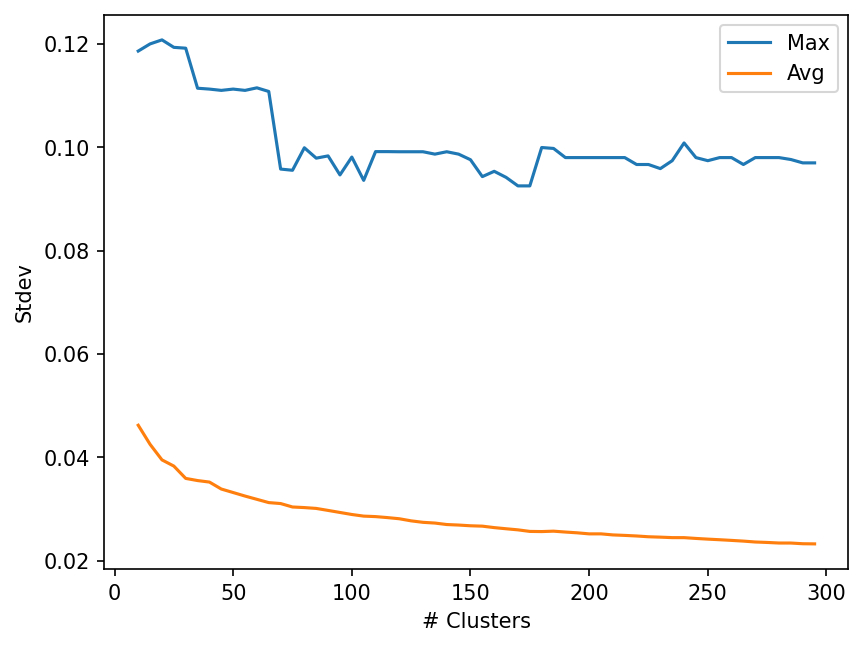

In [11]:
# Do simple k-means clustering on the dataset
# We will use a higher number of clusters than necessary since we want relatively fine control over what definitions are!
# Do not need to redo this: identified the ideal k = 70

from sklearn.cluster import KMeans
plt.style.use('default')

max_stds = []
avg_stds = []
for i in range(10, 300, 5):
    kmeans = KMeans(n_clusters = i, random_state = 0) # Need to seed the KMeans for reproducability!
    reprocess.loc[:, "cluster"] = kmeans.fit_predict(reprocess[rf.classes_])
    sample = reprocess.sample(10000)
    
    # fig, ax = plt.subplots(figsize=(5, 5), dpi=150)
    # ax.scatter(sample["UMAP 1"], sample["UMAP 2"], c=sample["cluster"], s=0.5)
    
    # Find maximal std
    stds = reprocess[[*rf.classes_, "cluster"]].groupby("cluster").std()
    max_std = np.max(stds)
    max_stds.append(max_std)
    avg_std = np.average(stds)
    avg_stds.append(avg_std)

fig, ax = plt.subplots(dpi=150)
ax.plot(range(10, 300, 5), max_stds, label="Max")
ax.plot(range(10, 300, 5), avg_stds, label="Avg")
ax.set(xlabel="# Clusters", ylabel="Stdev")
ax.legend()

/tmp/SLURM_1981031/ipykernel_246211/2157819695.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reprocess.loc[:, "cluster"] = kmeans.fit_predict(reprocess[rf.classes_])


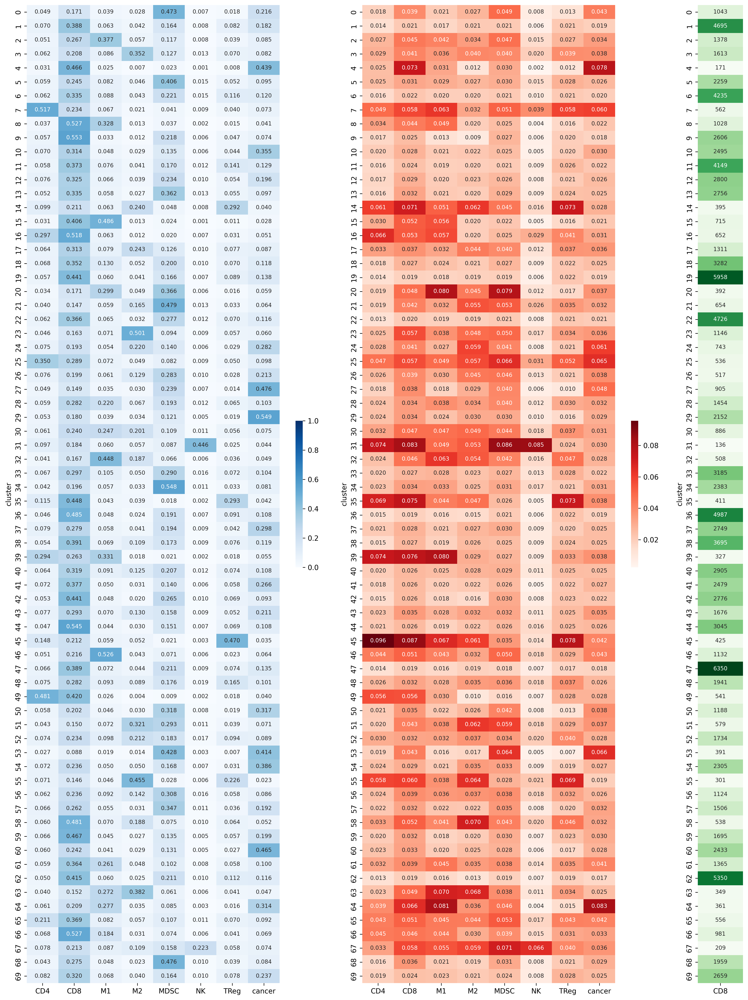

In [23]:
from sklearn.cluster import KMeans

n_clust = 70 # Optimal number of clusters identified above!

kmeans = KMeans(n_clusters = n_clust, random_state = 0) # Need to seed the KMeans for reproducability!
reprocess.loc[:, "cluster"] = kmeans.fit_predict(reprocess[rf.classes_])
sample = reprocess.sample(10000)

# Extract statistics
means = reprocess[[*rf.classes_, "cluster"]].groupby("cluster").mean()
stds = reprocess[[*rf.classes_, "cluster"]].groupby("cluster").std()
size = reprocess[["CD8", "cluster"]].groupby("cluster").count()

# Now plot the reprocessing clusters themselves
plt.style.use('default')
fig, ax = plt.subplots(1, 3, figsize=(15, 20), dpi=300, gridspec_kw={'width_ratios': [7, 7, 1]})
sns.heatmap(means, ax=ax[0], annot=True, fmt=".3f", cbar_kws={"shrink": 0.15}, annot_kws={"size" : 8}, cmap="Blues", vmin=0, vmax=1)
sns.heatmap(stds, ax=ax[1], annot=True, fmt=".3f", cbar_kws={"shrink": 0.15}, annot_kws={"size" : 8}, cmap="Reds")
sns.heatmap(size, ax=ax[2], annot=True, fmt="d", annot_kws={"size" : 8}, cmap="Greens", cbar=False)
fig.tight_layout()

In [24]:
def rf_reprocess_type(cprobs):

    cluster_probs = cprobs.copy()
    lymphoid = ["CD4", "CD8", "NK", "TReg"]
    p_lymphoid = sum(cluster_probs[lymphoid])
    myeloid = ["M1", "M2", "MDSC"]
    p_myeloid = sum(cluster_probs[myeloid])

    probs = cluster_probs.to_numpy().copy()
    probs.sort()
    probs = probs[::-1]

    P1 = cluster_probs.idxmax()
    P2 = cluster_probs.drop(P1).idxmax()

    # Class 1 clusters
    if (probs[0] > 0.5) and (probs[1] < 0.5*probs[0]):
        return (P1, 1)

    # Class 2 clusters
    if (probs[0] > 0.4) and (probs[1] < 0.5*probs[0]):
        return (P1, 2)
        
    # Class 3 clusters
    if (probs[0] > 0.4) and (probs[1] < 0.65*probs[0]):
        return (P1, 3)

    # Class 4 clusters
    if (probs[1] > 0.3): # Implied that p_P1 > 0.3
        if (P1 in lymphoid) and (P2 in lymphoid):
            return ("lymphoid", 4)
        if (P1 in myeloid) and (P2 in myeloid):
            return ("myeloid", 4)
        return ("stromal", 4)

    """
    # Class 5 clusters
    if (probs[1] > 0.25): # Implied that p_P1 > 0.25
        if (P1 in lymphoid) and (P2 in lymphoid):
            return ("lymphoid", 5)
        if (P1 in myeloid) and (P2 in myeloid):
            return ("myeloid", 5)
        return ("stromal", 5)

    if (probs[1] > 0.2) and (probs[1] + 0.16 > probs[0]):
        if (P1 in lymphoid) and (P2 in lymphoid):
            return ("lymphoid", 5)
        if (P1 in myeloid) and (P2 in myeloid):
            return ("myeloid", 5)
        return ("stromal", 5)
    """
    
    # Class 6 clusters
    if p_lymphoid > p_myeloid + 0.15:
        return("lymphoid", 6)
    if p_myeloid > p_lymphoid + 0.15:
        return("myeloid", 6)
    return ("stromal", 6)

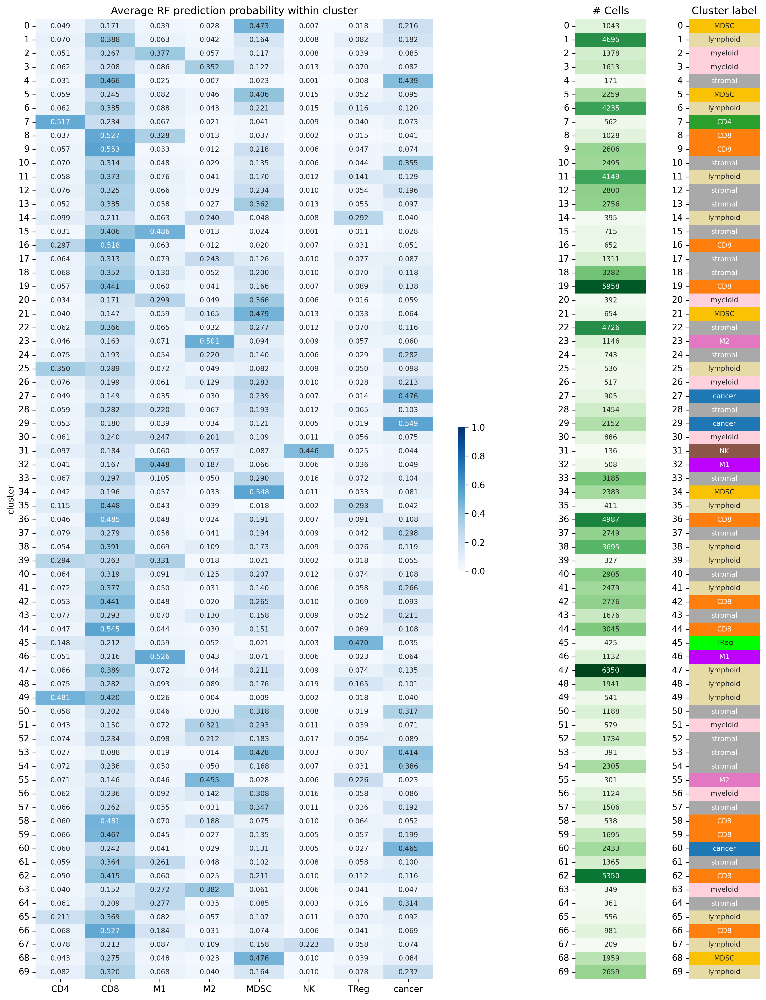

In [25]:
# Plotting prep stuff
fixed_name_to_type = {"M1" : 0, "M2" : 1, "cancer" : 2, "CD4" : 3, "TReg" : 4, "CD8" : 5, "NK" : 6, "MDSC" : 7, "myeloid" : 8, "lymphoid" : 9, "stromal" : 10}
apply_fixed_type = lambda x : fixed_name_to_type[x]
fixed_cell_colors = [
    'xkcd:lilac', # M0
    'xkcd:bright purple', # M1
    'tab:pink', # M2
    'tab:blue', # cancer
    'tab:green', # CD4 T helper
    'lime', # CD4 TReg
    'tab:orange', # CD8
    'tab:brown', # NK cell
    'xkcd:goldenrod', # MDSC
    'xkcd:light pink', # Myeloid
    'xkcd:beige', # Lymphoid
    'darkgray' # Stromal
] 
fixed_cell_cmap = mcolors.ListedColormap(fixed_cell_colors)

# Get labels
labels = means.apply(rf_reprocess_type, axis=1)
labels = labels.apply(pd.Series)
labels.columns = ["label", "cluster_type"]

labeled_clusters = pd.concat([means, labels], axis=1)
labeled_clusters["num_type"] = labeled_clusters["label"].astype(str).apply(apply_fixed_type)

# Plotting
plt.style.use('default')
fig, ax = plt.subplots(1, 3, figsize=(15, 20), dpi=300, gridspec_kw={'width_ratios': [7, 1, 1]})
sns.heatmap(labeled_clusters[rf.classes_], ax=ax[0], annot=True, fmt=".3f", cbar_kws={"shrink": 0.15}, annot_kws={"size" : 8}, cmap="Blues", vmin=0, vmax=1)
sns.heatmap(size, ax=ax[1], annot=True, fmt="d", annot_kws={"size" : 8}, cmap="Greens", cbar=False, xticklabels=False)
sns.heatmap(pd.DataFrame(labeled_clusters["num_type"]), ax=ax[2], annot=pd.DataFrame(labeled_clusters["label"]), fmt="", annot_kws={"size" : 8}, cmap=fixed_cell_cmap, cbar=False, vmin=-1, vmax=11, xticklabels=False)

ax[0].set(title="Average RF prediction probability within cluster")
ax[0].tick_params(axis='y', rotation=0)
ax[1].set(title="# Cells", xlabel="", ylabel="")
ax[1].tick_params(axis='y', rotation=0)
ax[2].set(title="Cluster label", xlabel="", ylabel="")
ax[2].tick_params(axis='y', rotation=0)

In [26]:
cluster_label_dict = dict(zip(labeled_clusters.index, labeled_clusters["label"]))
cluster_to_type = lambda x : cluster_label_dict[x]

reprocess["cluster_celltype"] = reprocess["cluster"].apply(cluster_to_type)

labels = reprocess[rf.classes_].apply(rf_reprocess_type, axis=1)
labels = labels.apply(pd.Series)
labels.columns = ["label", "cluster_type"]
reprocess["individual_celltype"] = labels["label"]

/tmp/SLURM_1981031/ipykernel_246211/391865453.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reprocess["cluster_celltype"] = reprocess["cluster"].apply(cluster_to_type)
/tmp/SLURM_1981031/ipykernel_246211/391865453.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reprocess["individual_celltype"] = labels["label"]


Text(0.5, 0.98, 'Confusion matrix normalized across cluster label')

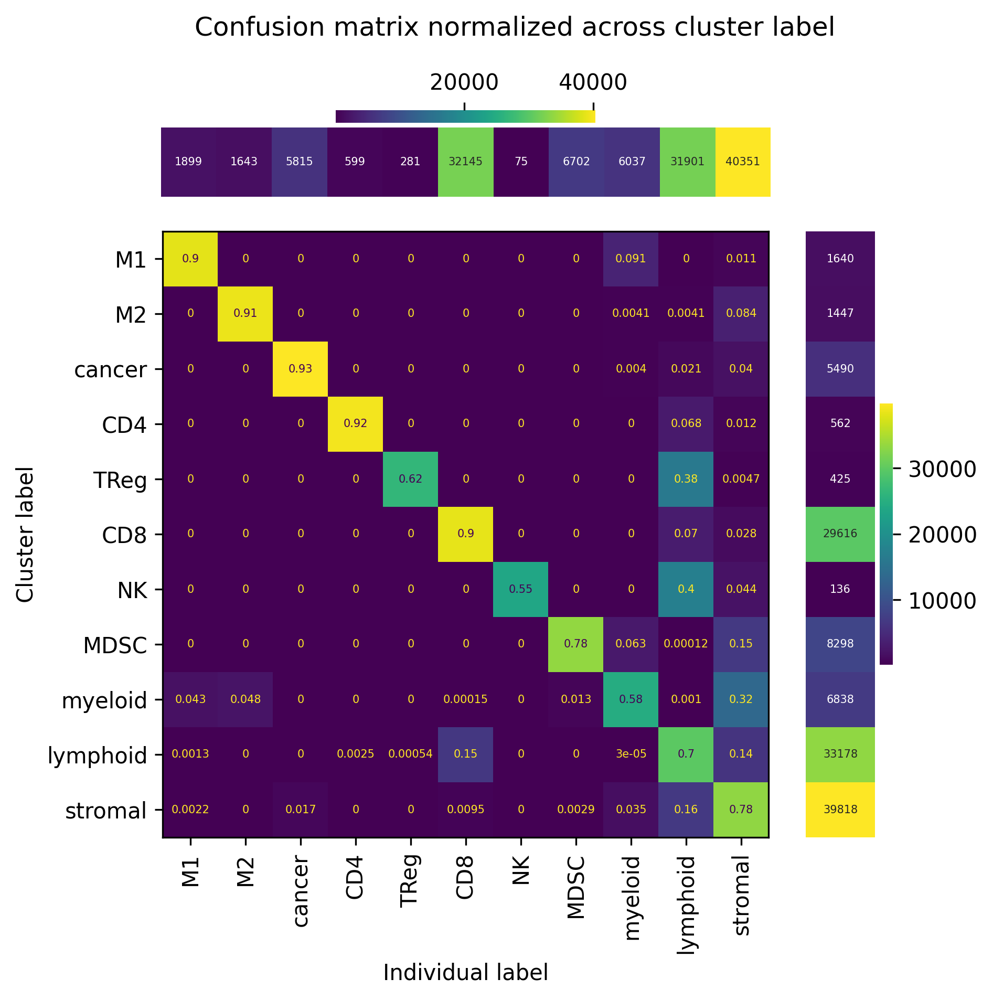

In [27]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix(reprocess["cluster_celltype"], reprocess["individual_celltype"], normalize='true', labels=list(fixed_name_to_type.keys())),
                             display_labels=fixed_name_to_type.keys())

cmap_shared = "viridis"
fig, ax = plt.subplots(2, 2, figsize=(6, 6), dpi=300, width_ratios=[7, 1], height_ratios=[1, 7], gridspec_kw={'hspace': 0.1, 'wspace': 0.1})
disp.plot(xticks_rotation="vertical", ax=ax[1, 0], text_kw={"size" : 5}, colorbar=False, cmap=cmap_shared)
ax[1, 0].set(ylabel="Cluster label", xlabel="Individual label")
sns.heatmap(pd.DataFrame(reprocess["cluster_celltype"].value_counts()[fixed_name_to_type.keys()]), fmt="d", ax=ax[1, 1], yticklabels=False, xticklabels=False, cmap=cmap_shared, annot=True, annot_kws={"size" : 5})
ax[1, 1].set(ylabel="")
sns.heatmap(pd.DataFrame(reprocess["individual_celltype"].value_counts()[fixed_name_to_type.keys()]).transpose(), fmt="d", ax=ax[0, 0], xticklabels=False, yticklabels=False, cmap=cmap_shared, annot=True, annot_kws={"size" : 5}, cbar_kws = dict(location="top"))
ax[0, 0].set(xlabel="")
ax[0, 1].set_visible(False)
fig.suptitle("Confusion matrix normalized across cluster label")

[Text(0.5, 1.0, 'Kept P1 labels where p_P1 > 0.6'),
 Text(0.5, -54.83333333333334, '')]

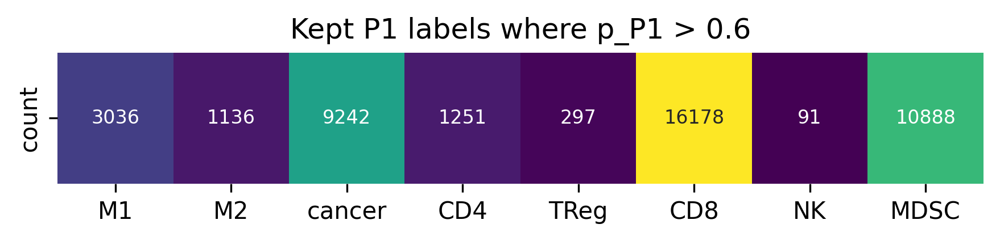

In [28]:
fig, ax = plt.subplots(figsize=(7,1), dpi=300)
sns.heatmap(pd.DataFrame(keep["P1"].value_counts()[list(fixed_name_to_type.keys())[:-3]]).transpose(), fmt="d", ax=ax, cmap=cmap_shared, annot=True, annot_kws={"size" : 8}, cbar=False)
ax.set(title="Kept P1 labels where p_P1 > 0.6", xlabel="")

In [37]:
pd.options.mode.chained_assignment = None

# This script will save CSVs and generate images
base_folder = "final_reclass"
RF1_folder = "first"
clust_folder = "clust"
indv_folder = "indv"
im_folder = "images"

cells = ["M0", "M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC", "myeloid", "lymphoid", "stromal"]
reverse_fixed = {value: key for key, value in fixed_name_to_type.items()}
apply_reverse_fixed = lambda x : reverse_fixed[x]

def vcs_to_array(vcs):
    array = np.zeros(12)
    for i, cell in enumerate(cells):
        if cell in vcs.keys():
            array[i] = vcs[cell]
    return array

for i, pred_df in enumerate(predicted_met_dfs):

    # Get the correct cells
    df = pred_df.copy()
    met_name = names[i]
    knowns = df[df["origin"] == 0]
    keeps = keep[keep["metastasis"] == met_name]
    keeps.loc[:, "num_type"] = keeps["P1"].apply(apply_fixed_type)
    reproc = reprocess[reprocess["metastasis"] == met_name]
    reproc["clust_num_type"] = reproc["cluster_celltype"].apply(apply_fixed_type)
    reproc["indv_num_type"] = reproc["individual_celltype"].apply(apply_fixed_type)

    # Stream datasets together
    keys_1 = ["shiftedData1", "shiftedData2", "num_type"]
    keys_2 = ["shiftedData1", "shiftedData2", "clust_num_type"]
    keys_3 = ["shiftedData1", "shiftedData2", "indv_num_type"]
    cluster_all = pd.concat([knowns[keys_1], keeps[keys_1], reproc[keys_2]])
    cluster_all["num_type"] = cluster_all["num_type"].combine_first(cluster_all["clust_num_type"])
    cluster_all = cluster_all.drop(columns=["clust_num_type"])
    cluster_all["celltype"] = cluster_all["num_type"].apply(apply_reverse_fixed)
    indv_all = pd.concat([knowns[keys_1], keeps[keys_1], reproc[keys_3]])
    indv_all["num_type"] = indv_all["num_type"].combine_first(indv_all["indv_num_type"])
    indv_all = indv_all.drop(columns=["indv_num_type"])
    indv_all["celltype"] = indv_all["num_type"].apply(apply_reverse_fixed)

    # Force coordinates
    # cluster_all["shiftedData1"] = df["shiftedData1"]
    # cluster_all["shiftedData2"] = df["shiftedData2"]
    # indv_all["shiftedData1"] = df["shiftedData1"]
    # indv_all["shiftedData2"] = df["shiftedData2"]

    # Plot
    fig, ax = plt.subplots(2, 4, figsize=(20, 7), dpi=300, width_ratios=[8, 8, 8, 0.5], height_ratios=[8, 1])

    im = df.plot.scatter("shiftedData1", "shiftedData2", c="num_type", cmap=fixed_cell_cmap, clim=[-1, 11], ax=ax[0, 0], colorbar=False, s=2)
    ax[0, 0].set(title="Only 1st RF imputation")
    sns.heatmap([np.arange(12)], cmap=fixed_cell_cmap, ax=ax[1,0], cbar=False, 
                annot=[vcs_to_array(df["celltype"].value_counts())], fmt="n", annot_kws={"size" : 8},
                xticklabels=False, yticklabels=False)
    df["num_type"] = df["num_type"] + 1 # We eliminated M0 previously, so need to increment by 1 for model
    df["num_type"] = df["num_type"].replace({7:8, 8:10, 9:11, 10:12, 11:13}, inplace=False) # We also need to adjust NK, MDSC, Myeloid, Lymphoid, and Stromal populations
    df.to_csv(os.path.join(base_folder, RF1_folder, met_name[17:-11]) + "_rf1.csv", columns=keys_1, header=False)
    
    cluster_all.plot.scatter("shiftedData1", "shiftedData2", c="num_type", cmap=fixed_cell_cmap, clim=[-1, 11], ax=ax[0, 1], colorbar=False, s=2)
    ax[0, 1].set(title="Cluster labeling of unconfident cells")
    sns.heatmap([np.arange(12)], cmap=fixed_cell_cmap, ax=ax[1,1], cbar=False, 
                annot=[vcs_to_array(cluster_all["celltype"].value_counts())], fmt="n", annot_kws={"size" : 8},
                xticklabels=False, yticklabels=False)
    cluster_all["num_type"] = cluster_all["num_type"] + 1 # We eliminated M0 previously, so need to increment by 1 for model
    cluster_all["num_type"] = cluster_all["num_type"].replace({7:8, 8:10, 9:11, 10:12, 11:13}) # We also need to adjust NK, MDSC, Myeloid, Lymphoid, and Stromal populations
    cluster_all.to_csv(os.path.join(base_folder, clust_folder, met_name[17:-11]) + "_clust.csv", columns=keys_1, header=False)
    
    indv_all.plot.scatter("shiftedData1", "shiftedData2", c="num_type", cmap=fixed_cell_cmap, clim=[-1, 11], ax=ax[0, 2], colorbar=False, s=2)
    ax[0, 2].set(title="Individual labeling of unconfident cells")
    sns.heatmap([np.arange(12)], cmap=fixed_cell_cmap, ax=ax[1,2], cbar=False, 
                annot=[vcs_to_array(indv_all["celltype"].value_counts())], fmt="n", annot_kws={"size" : 8},
                xticklabels=False, yticklabels=False)
    indv_all["num_type"] = indv_all["num_type"] + 1 # We eliminated M0 previously, so need to increment by 1 for model
    indv_all["num_type"] = indv_all["num_type"].replace({7:8, 8:10, 9:11, 10:12, 11:13}) # We also need to adjust NK, MDSC, Myeloid, Lymphoid, and Stromal populations
    indv_all.to_csv(os.path.join(base_folder, indv_folder, met_name[17:-11]) + "_indv.csv", columns=keys_1, header=False)
    
    fig.colorbar(im.collections[0], cax=ax[0, 3])
    ax[0, 3].set_yticks(np.arange(len(cell_colors))-0.5, ["M0", "M1", "M2", "Cancer", "Th", "Treg", "CD8", "NK", "MDSC", "Myeloid", "Lymphoid", "Stromal"], rotation=0)
    ax[1, 3].set_visible(False)
    
    fig.suptitle(met_name[17:-11])
    fig.tight_layout()
    fig.savefig(os.path.join(base_folder, im_folder, met_name[17:-11]) + ".png", dpi=300)
    plt.close(fig)

In [43]:
len(indv_dfs.keys())

77

In [65]:
filt_vcs["id"] = np.arange(0, len(filt_vcs))
filt_vcs[["id", "n_cells", "in_cancer_%", "nongeneral_%"]]

/tmp/SLURM_2093574/ipykernel_510395/1366652897.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filt_vcs["id"] = np.arange(0, len(filt_vcs))


,id,n_cells,in_cancer_%,nongeneral_%
#31 NeuN NT2.5 LM 4 wks #4_met_9_region1,0,2518.0,0.260921,0.730342
#02 NT2.5 LM Lungs 10d-2_met_1_region1,1,4114.0,0.003160,0.848080
#03 NT2.5 LM Lungs 10d-3_met_3_region1,2,1664.0,0.000000,0.998197
#13 NT2.5 LM Lungs 22d-4_met_3_region1,3,5587.0,0.007696,0.913191
#15 NT2.5 LM d122 UN TX 1_met_11_region1,4,180.0,0.011111,0.783333
#25 NeuN NT2.5 LM 5 wks #1_met_4_region1,5,303.0,0.006601,0.603960
#16 NT2.5 LM d122 V1_met_1_region1,6,1512.0,0.029101,0.830026
#31 NeuN NT2.5 LM 4 wks #4_met_7_region1,7,3439.0,0.574586,0.726083
#29 NeuN NT2.5 LM 4 wks #2_met_10_region1,8,2145.0,0.433100,0.790210
#22 7 days Untx-4_met_4_region2,9,209.0,0.000000,0.636364


In [3]:
# Import CSVs
base_folder = "final_reclass"
RF1_folder = "first"
clust_folder = "clust"
indv_folder = "indv"

RF1_dfs = {}
clust_dfs = {}
indv_dfs = {}

for file in os.listdir(os.path.join(base_folder, RF1_folder)):
    path = os.path.join(base_folder, RF1_folder, file)
    df = pd.read_csv(path, header=None, names=["shiftedData1", "shiftedData2", "celltype"])
    name = file[:-8]
    RF1_dfs[name] = df

for file in os.listdir(os.path.join(base_folder, clust_folder)):
    path = os.path.join(base_folder, clust_folder, file)
    df = pd.read_csv(path, header=None, names=["shiftedData1", "shiftedData2", "celltype"])
    name = file[:-10]
    clust_dfs[name] = df

for file in os.listdir(os.path.join(base_folder, indv_folder)):
    path = os.path.join(base_folder, indv_folder, file)
    df = pd.read_csv(path, header=None, names=["shiftedData1", "shiftedData2", "celltype"])
    name = file[:-9]
    indv_dfs[name] = df

# Get value_counts
vc_df = pd.DataFrame()
num_to_type = {0: "M0", 1: "M1", 2: "M2", 3: "cancer", 4: "CD4", 5: "Treg", 6: "CD8", 8: "NK", 10: "MDSC", 11: "myeloid", 12: "lymphoid", 13: "stromal"}
cells = ["M0", "M1", "M2", "cancer", "CD4", "Treg", "CD8", "NK", "MDSC", "myeloid", "lymphoid", "stromal"]

vcs = []
names = []

def vcs_to_array(vcs):
    array = np.zeros(12)
    for i, cell in enumerate(cells):
        if cell in vcs.keys():
            array[i] = vcs[cell]
    return array
    
for key in RF1_dfs.keys():
    # Get value counts for ALL cell types across all methodologies
    rf_vc = RF1_dfs[key]["celltype"].apply(lambda x: num_to_type[x]).value_counts()
    cl_vc = clust_dfs[key]["celltype"].apply(lambda x: num_to_type[x]).value_counts()
    in_vc = indv_dfs[key]["celltype"].apply(lambda x: num_to_type[x]).value_counts()
    vcs.append(np.concatenate((vcs_to_array(rf_vc), vcs_to_array(cl_vc), vcs_to_array(in_vc))))
    names.append(key)

# Get value counts into the right format
vcs = np.array(vcs)
vc_df = pd.DataFrame(vcs, columns=[*["rf_"+cell for cell in cells], *["cl_" + cell for cell in cells], *["in_"+cell for cell in cells]])
vc_df.index = names

lymphoid = ["CD4", "CD8", "NK", "Treg", "lymphoid"]
myeloid = ["M0", "M1", "M2", "MDSC", "myeloid"]
pro_tumor = ["M2", "Treg", "MDSC"]
anti_tumor = ["M1", "CD4", "CD8", "NK"]

# Summary columns -- everything except for n_cells is a % of total
vc_df["n_cells"] = vc_df[["rf_"+cell for cell in cells]].astype(np.float32).sum(axis=1)
vc_df["rf_lymphoid"] = vc_df[["rf_"+cell for cell in lymphoid]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["cl_lymphoid"] = vc_df[["cl_"+cell for cell in lymphoid]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["in_lymphoid"] = vc_df[["in_"+cell for cell in lymphoid]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["rf_myeloid"] = vc_df[["rf_"+cell for cell in myeloid]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["cl_myeloid"] = vc_df[["cl_"+cell for cell in myeloid]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["in_myeloid"] = vc_df[["in_"+cell for cell in myeloid]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["rf_pro_tumor"] = vc_df[["rf_"+cell for cell in pro_tumor]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["cl_pro_tumor"] = vc_df[["cl_"+cell for cell in pro_tumor]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["in_pro_tumor"] = vc_df[["in_"+cell for cell in pro_tumor]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["rf_anti_tumor"] = vc_df[["rf_"+cell for cell in anti_tumor]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["cl_anti_tumor"] = vc_df[["cl_"+cell for cell in anti_tumor]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["in_anti_tumor"] = vc_df[["in_"+cell for cell in anti_tumor]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]

# More summary columns
vc_df["in_cancer_%"] = vc_df["in_cancer"] / vc_df["n_cells"]
vc_df["in_func_immune_%"] = vc_df["in_pro_tumor"] + vc_df["in_anti_tumor"]
vc_df["nongeneral_%"] = vc_df["in_cancer_%"] + vc_df["in_func_immune_%"]
vc_df["in_CD8_%"] = vc_df["in_CD8"] / vc_df["n_cells"]
vc_df["in_MDSC_%"] = vc_df["in_MDSC"] / vc_df["n_cells"]
vc_df["in_M1_%"] = vc_df["in_M1"] / vc_df["n_cells"]
vc_df["in_M2_%"] = vc_df["in_M2"] / vc_df["n_cells"]
vc_df["in_cancer_%"] = vc_df["in_cancer"] / vc_df["n_cells"]
vc_df["in_immune_%"] = vc_df["in_myeloid"] + vc_df["in_lymphoid"]

filt_vcs = vc_df[vc_df["nongeneral_%"] >= 0.6]
rejects = vc_df[vc_df["nongeneral_%"] < 0.6]

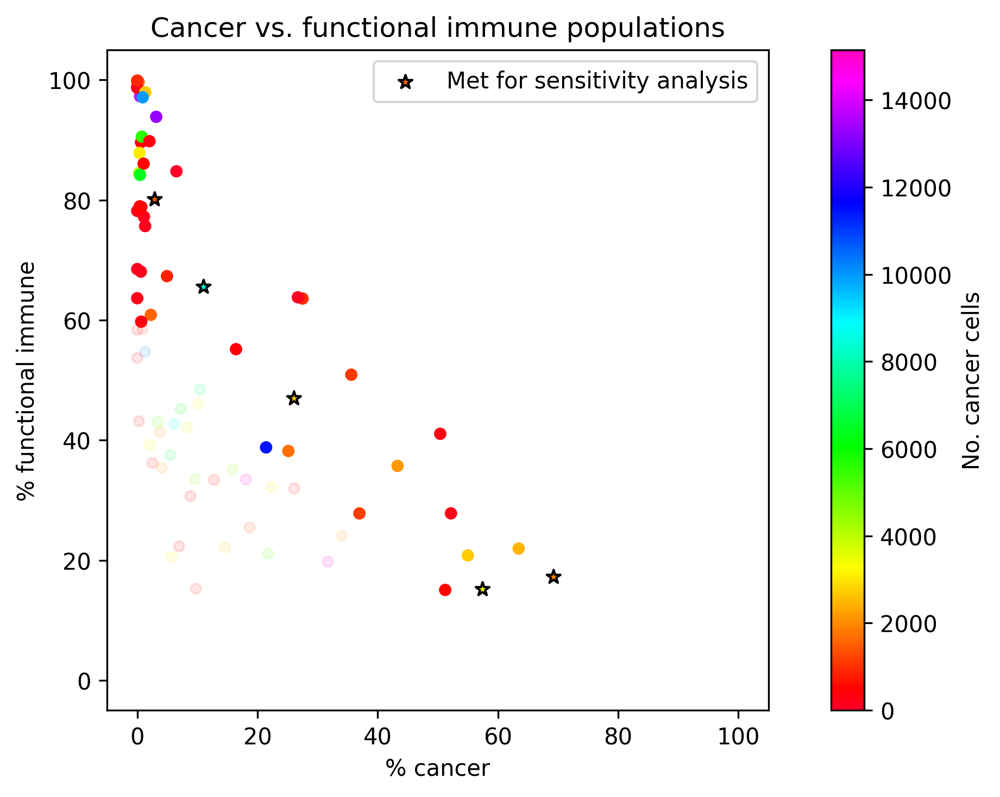

In [4]:
plt.style.use('default')
pd.options.mode.chained_assignment = None
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

sa_mets = ["#16 NT2.5 LM d122 V1_met_1_region1",
           "#31 NeuN NT2.5 LM 4 wks #4_met_9_region1",
           "#31 NeuN NT2.5 LM 4 wks #4_met_10_region1",
           "#29 NeuN NT2.5 LM 4 wks #2_met_8_region1",
           "#31 NeuN NT2.5 LM 4 wks #4_met_7_region1"]

sa_vcs = filt_vcs.loc[sa_mets]
nonsa_vcs = filt_vcs.loc[filt_vcs.index.difference(sa_mets)]

sa_vcs["% cancer"] = sa_vcs["in_cancer_%"] * 100
sa_vcs["% functional immune"] = sa_vcs["in_func_immune_%"]  * 100
sa_vcs.plot.scatter("% cancer", "% functional immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=40, clim=[0, max(vc_df["n_cells"])], 
                    edgecolor="k", marker="*", label="Met for sensitivity analysis")

nonsa_vcs["% cancer"] = nonsa_vcs["in_cancer_%"] * 100
nonsa_vcs["% functional immune"] = nonsa_vcs["in_func_immune_%"]  * 100
nonsa_vcs.plot.scatter("% cancer", "% functional immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, clim=[0, max(vc_df["n_cells"])])

rejects["% cancer"] = rejects["in_cancer_%"] * 100
rejects["% functional immune"] = rejects["in_func_immune_%"] * 100
rejects.plot.scatter("% cancer", "% functional immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, alpha=.10, clim=[0, max(vc_df["n_cells"])])

ax.set(title="Cancer vs. functional immune populations")
ax.figure.colorbar(ax.collections[0]).set_label("No. cancer cells")

ax.set_xlim(-5, 105)
ax.set_ylim(-5, 105)
ax.set_aspect('equal')
fig.tight_layout()

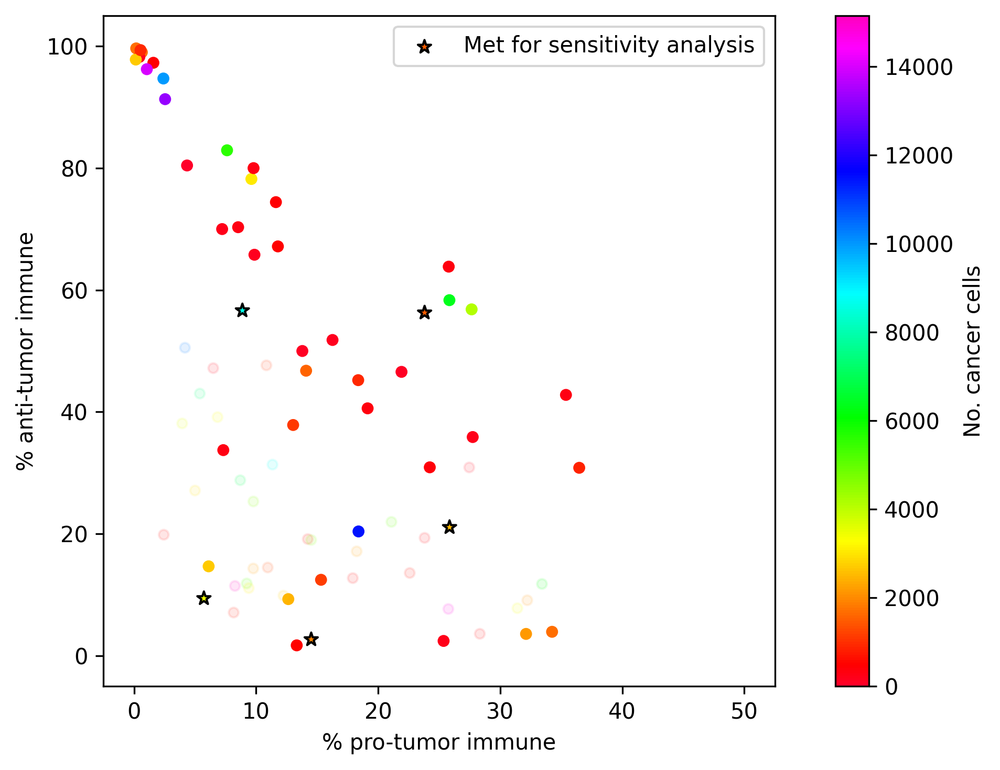

In [14]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

sa_vcs["% pro-tumor immune"] = sa_vcs["in_pro_tumor"] * 100
sa_vcs["% anti-tumor immune"] = sa_vcs["in_anti_tumor"]  * 100
sa_vcs.plot.scatter("% pro-tumor immune", "% anti-tumor immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=40, clim=[0, max(vc_df["n_cells"])], 
                    edgecolor="k", marker="*", label="Met for sensitivity analysis")

nonsa_vcs["% pro-tumor immune"] = nonsa_vcs["in_pro_tumor"] * 100
nonsa_vcs["% anti-tumor immune"] = nonsa_vcs["in_anti_tumor"]  * 100
nonsa_vcs.plot.scatter("% pro-tumor immune", "% anti-tumor immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, clim=[0, max(vc_df["n_cells"])])

rejects["% pro-tumor immune"] = rejects["in_pro_tumor"] * 100
rejects["% anti-tumor immune"] = rejects["in_anti_tumor"] * 100
rejects.plot.scatter("% pro-tumor immune", "% anti-tumor immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, alpha=.10, clim=[0, max(vc_df["n_cells"])])

ax.figure.colorbar(ax.collections[0]).set_label("No. cancer cells")

ax.set_xlim(-2.5, 52.5)
ax.set_ylim(-5, 105)
ax.set_aspect(50/100)
fig.tight_layout()

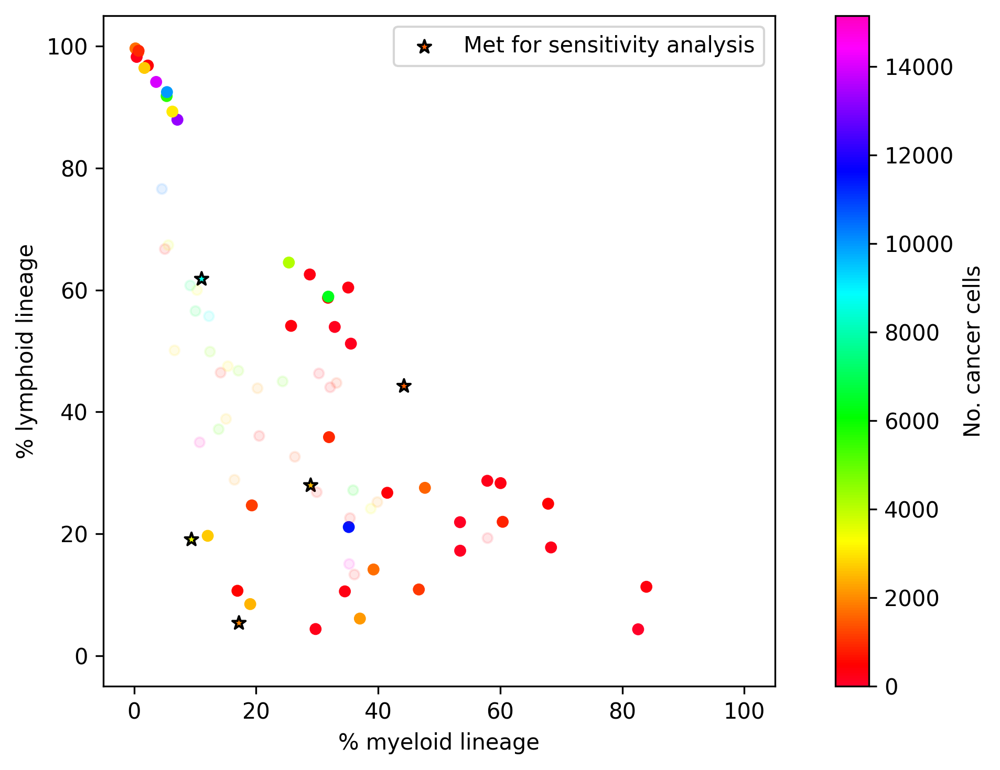

In [6]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

sa_vcs["% myeloid lineage"] = sa_vcs["in_myeloid"] * 100
sa_vcs["% lymphoid lineage"] = sa_vcs["in_lymphoid"]  * 100
sa_vcs.plot.scatter("% myeloid lineage", "% lymphoid lineage", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=40, clim=[0, max(vc_df["n_cells"])], 
                    edgecolor="k", marker="*", label="Met for sensitivity analysis")

nonsa_vcs["% myeloid lineage"] = nonsa_vcs["in_myeloid"] * 100
nonsa_vcs["% lymphoid lineage"] = nonsa_vcs["in_lymphoid"]  * 100
nonsa_vcs.plot.scatter("% myeloid lineage", "% lymphoid lineage", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, clim=[0, max(vc_df["n_cells"])])

rejects["% myeloid lineage"] = rejects["in_myeloid"] * 100
rejects["% lymphoid lineage"] = rejects["in_lymphoid"] * 100
rejects.plot.scatter("% myeloid lineage", "% lymphoid lineage", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, alpha=.10, clim=[0, max(vc_df["n_cells"])])

ax.figure.colorbar(ax.collections[0]).set_label("No. cancer cells")

ax.set_xlim(-5, 105)
ax.set_ylim(-5, 105)
ax.set_aspect(100/100)
fig.tight_layout()

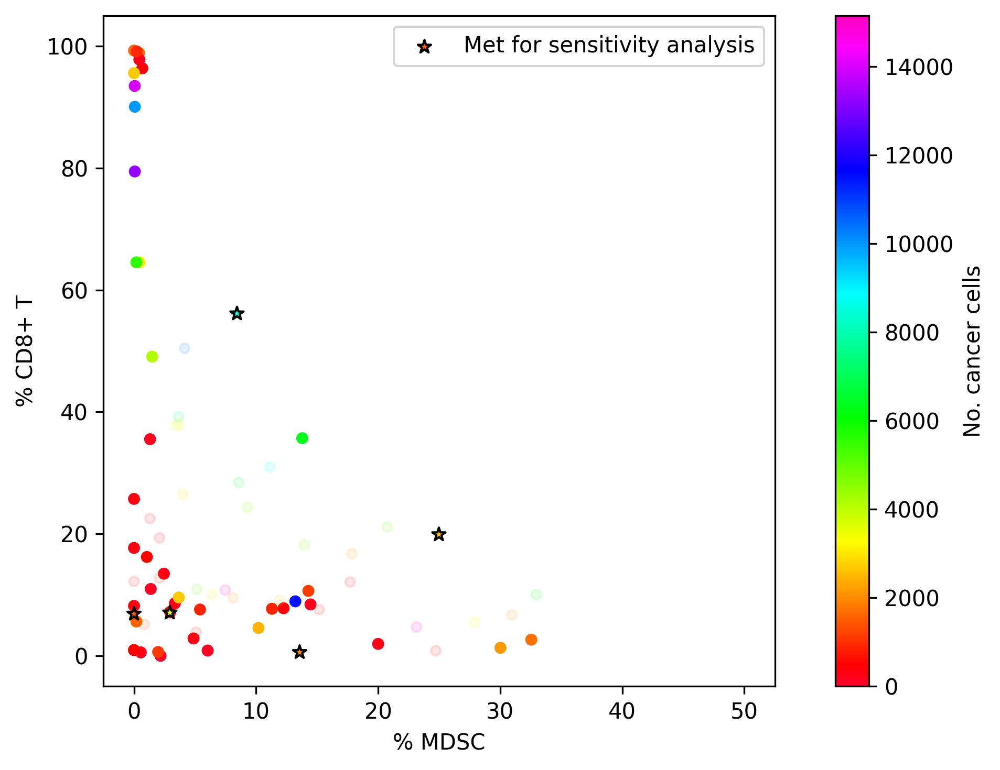

In [7]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

nonsa_vcs["% MDSC"] = nonsa_vcs["in_MDSC_%"] * 100
nonsa_vcs["% CD8+ T"] = nonsa_vcs["in_CD8_%"]  * 100
nonsa_vcs.plot.scatter("% MDSC", "% CD8+ T", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, clim=[0, max(vc_df["n_cells"])])

rejects["% MDSC"] = rejects["in_MDSC_%"] * 100
rejects["% CD8+ T"] = rejects["in_CD8_%"] * 100
rejects.plot.scatter("% MDSC", "% CD8+ T", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, alpha=.10, clim=[0, max(vc_df["n_cells"])])

sa_vcs["% MDSC"] = sa_vcs["in_MDSC_%"] * 100
sa_vcs["% CD8+ T"] = sa_vcs["in_CD8_%"]  * 100
sa_vcs.plot.scatter("% MDSC", "% CD8+ T", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=40, clim=[0, max(vc_df["n_cells"])], 
                    edgecolor="k", marker="*", label="Met for sensitivity analysis")

ax.figure.colorbar(ax.collections[0]).set_label("No. cancer cells")

ax.set_xlim(-2.5, 52.5)
ax.set_ylim(-5, 105)
ax.set_aspect(50/100)
fig.tight_layout()

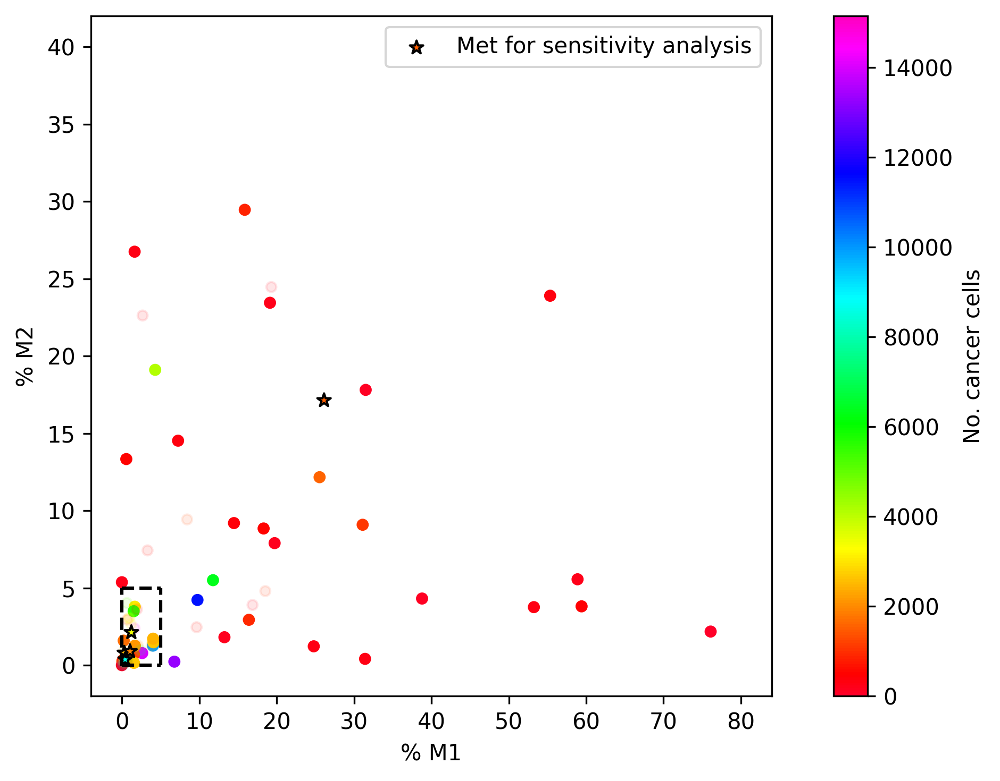

In [11]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

nonsa_vcs["% M1"] = nonsa_vcs["in_M1_%"] * 100
nonsa_vcs["% M2"] = nonsa_vcs["in_M2_%"]  * 100
nonsa_vcs.plot.scatter("% M1", "% M2", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, clim=[0, max(vc_df["n_cells"])])

rejects["% M1"] = rejects["in_M1_%"] * 100
rejects["% M2"] = rejects["in_M2_%"] * 100
rejects.plot.scatter("% M1", "% M2", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, alpha=.10, clim=[0, max(vc_df["n_cells"])])

sa_vcs["% M1"] = sa_vcs["in_M1_%"] * 100
sa_vcs["% M2"] = sa_vcs["in_M2_%"]  * 100
sa_vcs.plot.scatter("% M1", "% M2", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=40, clim=[0, max(vc_df["n_cells"])], 
                    edgecolor="k", marker="*", label="Met for sensitivity analysis")

ax.figure.colorbar(ax.collections[0]).set_label("No. cancer cells")

ax.axhline(5, 4/88, (4+5)/88, color="k", linestyle="dashed")
ax.axvline(5, 2/44, (2+5)/44, color="k", linestyle="dashed")
ax.axhline(0, 4/88, (4+5)/88, color="k", linestyle="dashed")
ax.axvline(0, 2/44, (2+5)/44, color="k", linestyle="dashed")

ax.set_xlim(-4, 84)
ax.set_ylim(-2, 42)
ax.set_aspect(2)
fig.tight_layout()

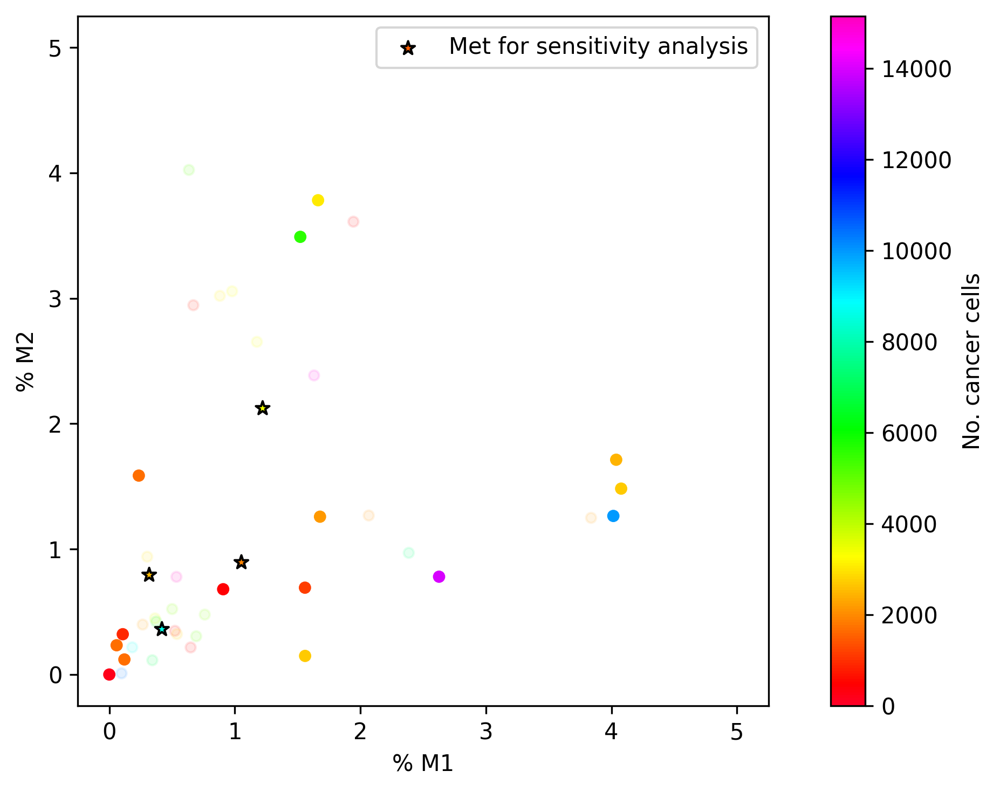

In [12]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

nonsa_vcs["% M1"] = nonsa_vcs["in_M1_%"] * 100
nonsa_vcs["% M2"] = nonsa_vcs["in_M2_%"]  * 100
nonsa_vcs.plot.scatter("% M1", "% M2", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, clim=[0, max(vc_df["n_cells"])])

rejects["% M1"] = rejects["in_M1_%"] * 100
rejects["% M2"] = rejects["in_M2_%"] * 100
rejects.plot.scatter("% M1", "% M2", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, alpha=.10, clim=[0, max(vc_df["n_cells"])])

sa_vcs["% M1"] = sa_vcs["in_M1_%"] * 100
sa_vcs["% M2"] = sa_vcs["in_M2_%"]  * 100
sa_vcs.plot.scatter("% M1", "% M2", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=40, clim=[0, max(vc_df["n_cells"])], 
                    edgecolor="k", marker="*", label="Met for sensitivity analysis")

ax.figure.colorbar(ax.collections[0]).set_label("No. cancer cells")

ax.set_xlim(-0.25, 5.25)
ax.set_ylim(-0.25, 5.25)
ax.set_aspect(100/100)
fig.tight_layout()

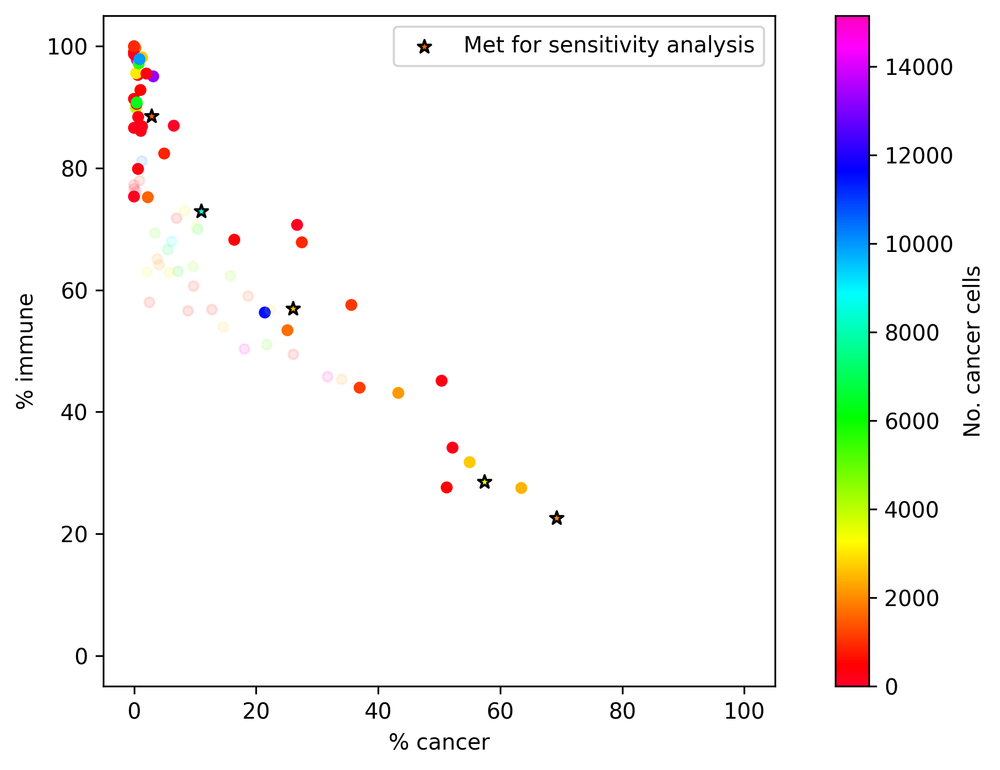

In [13]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

nonsa_vcs["% immune"] = nonsa_vcs["in_immune_%"]  * 100
nonsa_vcs.plot.scatter("% cancer", "% immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, clim=[0, max(vc_df["n_cells"])])

rejects["% immune"] = rejects["in_immune_%"] * 100
rejects.plot.scatter("% cancer", "% immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=20, alpha=.10, clim=[0, max(vc_df["n_cells"])])

sa_vcs["% immune"] = sa_vcs["in_immune_%"]  * 100
sa_vcs.plot.scatter("% cancer", "% immune", c="n_cells", ax=ax, colorbar=False, cmap="gist_rainbow", s=40, clim=[0, max(vc_df["n_cells"])], 
                    edgecolor="k", marker="*", label="Met for sensitivity analysis")

ax.figure.colorbar(ax.collections[0]).set_label("No. cancer cells")

ax.set_xlim(-5, 105)
ax.set_ylim(-5, 105)
ax.set_aspect(100/100)
fig.tight_layout()

In [65]:
# Turn all the countdata into a dataframe
orig_counts = pd.DataFrame(vc_orig)
fill_ins = pd.DataFrame(vc_top_pred)
orig_counts.loc[:, "id"] = [name[17:-11] for name in names]
fill_ins.loc[:, "id"] = [name[17:-11] for name in names]
orig_counts.set_index("id", inplace=True)
fill_ins.set_index("id", inplace=True)

# Fix issue w/ Treg and treg
orig_counts["TReg"] = orig_counts["Treg"] + orig_counts["treg"]
orig_counts.drop(["Treg", "treg"], axis=1, inplace=True)

# Get the total cell counts
orig_counts["tot"] = orig_counts.sum(axis=1)
fill_ins["tot"] = fill_ins.sum(axis=1)

# Convert to percentages
orig_percents = orig_counts.div(orig_counts["tot"], axis=0)
orig_percents.fillna(0, inplace=True)
orig_percents["ncells"] = orig_counts["tot"]
orig_percents["M0"] = np.zeros(len(orig_percents))

fill_percents = fill_ins.div(fill_ins["tot"], axis=0)
fill_percents.fillna(0, inplace=True)
fill_percents["ncells"] = fill_ins["tot"]
fill_percents["M0"] = np.zeros(len(fill_percents))

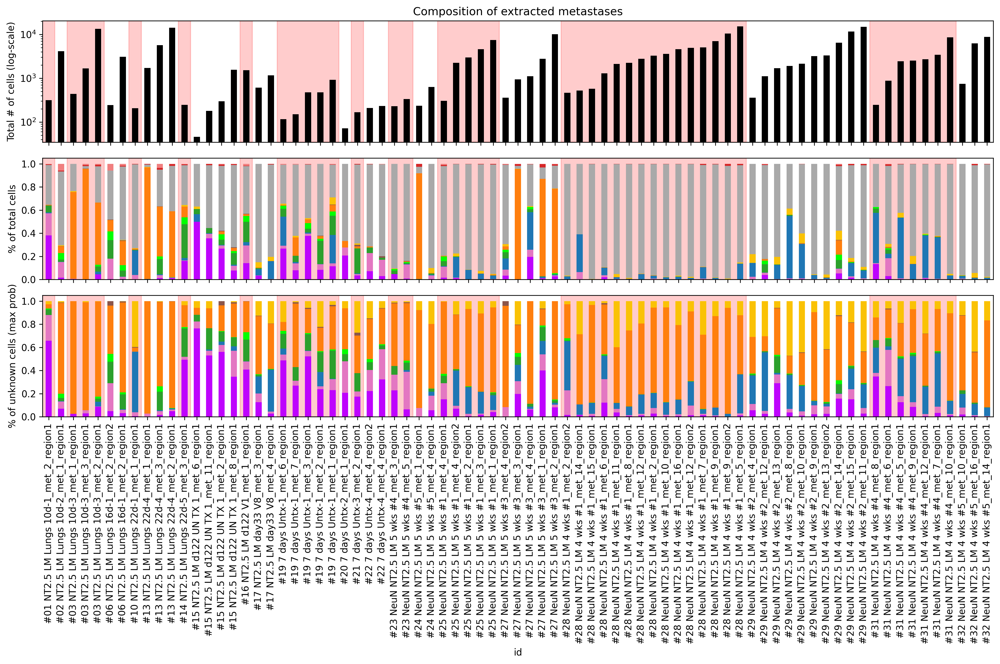

In [68]:
plt.style.use('default')

fig, ax = plt.subplots(3, 1, figsize=(15, 10), dpi=300, sharex=True)
orig_percents["group"] = [idx[:3] for idx in orig_percents.index]
fill_percents["group"] = [idx[:3] for idx in fill_percents.index]
orig_percents = orig_percents.sort_values(["group", "ncells"])
fill_percents = fill_percents.sort_values(["group", "ncells"])
cell_makeup = orig_percents[["M0", "M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC", "unknown", "error_type", "immune"]]
fill_makeup = fill_percents[["M0", "M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC"]]

switch_at = [0, 1, 2, 5, 7, 8, 11, 12, 16, 17, 19, 24, 25, 26, 28, 30, 32, 37, 42, 57, 67, 74]
for i in range(len(switch_at)//2):
    a = switch_at[2*i]
    b = switch_at[2*i + 1]
    ax[0].axvspan(a-0.5, b-0.5, color='red', alpha=0.2)
    ax[1].axvspan(a-0.5, b-0.5, color='red', alpha=0.2)
    ax[2].axvspan(a-0.5, b-0.5, color='red', alpha=0.2)
    
cell_makeup.plot(kind='bar', stacked=True, ax=ax[1], color=cell_cmap.colors, legend=False, xticks=np.arange(len(orig_percents))**2)
fill_makeup.plot(kind='bar', stacked=True, ax=ax[2], color=cell_cmap.colors, legend=False, xticks=np.arange(len(orig_percents))**2)

orig_percents["ncells"].plot(kind='bar', ax=ax[0], color="k")
ax[0].set_yscale('log')
ax[0].set(title="Composition of extracted metastases", ylabel="Total # of cells (log-scale)")
ax[1].set(ylabel="% of total cells")
ax[1].tick_params(axis='x', which='both', labelsize=5)
ax[2].set(ylabel="% of unknown cells (max prob)")

plt.tight_layout()
fig.savefig("extracted_met_full/compositions_filled.png", dpi=300)